# 02 - Climate data: fetch ERA5 and build indices

Fetches daily temperature and precipitation for the Piedmont wine districts
(2006 to 2023) and reduces each year to a set of climate indicators.

Source: the Open-Meteo historical API, whose archive is ERA5, delivered over a
fast HTTP API with no key and no request queue. The Copernicus CDS path
(`src/climate_ingest.py`) is kept as an official-source option but is slower.

In [1]:
# Locate the project root and make src/ + config importable.
import os, sys
d = os.getcwd()
while not os.path.exists(os.path.join(d, "config.py")) and os.path.dirname(d) != d:
    d = os.path.dirname(d)
os.chdir(d)
if d not in sys.path:
    sys.path.insert(0, d)
print("Project root:", d)

Project root: /Users/shreyshukla/Documents/ICS Project


In [2]:
import os, glob, pandas as pd, matplotlib.pyplot as plt
import config
from src import climate_ingest_openmeteo as om, climate_indices

## 1. Sampling points

We sample the wine districts (the hills and valleys where grapes grow) rather than
province centroids, several of which fall in the Alps and would bias the regional
climate cold. The points are defined in `config.WINE_DISTRICTS`.

In [3]:
pd.DataFrame(config.WINE_DISTRICTS, columns=['district','lat','lon'])

,district,lat,lon
0,Langhe (Alba),44.70,8.04
1,Roero,44.80,7.95
2,Monferrato (Asti),44.90,8.21
3,Acqui / Monferrato,44.68,8.47
4,Gavi / Tortonese,44.76,8.80
5,Alto Piemonte (Gattinara),45.62,8.36


## 2. Fetch and build indices

`om.main()` fetches daily max-temperature (pure ERA5 model) and precipitation for
each district, averages them into a regional series, computes the indices, and
writes `piedmont_climate_indices.csv`. Each district is cached under
`data/raw/openmeteo/`, so re-runs are fast and resilient to rate limits.

To use the CDS/ERA5 path instead: `from src import climate_ingest;
climate_ingest.main()` followed by `climate_indices.main()`.

In [4]:
climate = om.main()

Open-Meteo ingest for Piedmont, 2006 to 2023
  [cache] Langhe (Alba)
  [cache] Roero
  [cache] Monferrato (Asti)
  [cache] Acqui / Monferrato
  [cache] Gavi / Tortonese
  [cache] Alto Piemonte (Gattinara)

Climate indices -> /Users/shreyshukla/Documents/ICS Project/data/processed/piedmont_climate_indices.csv (18 years)
 year  summer_heatwave_days  summer_mean_tmax_c  growing_precip_mm
 2006                     0           25.349275         514.283333
 2007                    11           27.559964         431.583333
 2008                     0           24.461775         576.116667
 2009                    10           29.093659         532.483333
 2010                     7           27.818116         558.550000
 2011                     0           24.266667         478.300000
 2012                    10           28.934058         530.733333
 2013                    10           28.196196         712.016667
 2014                     7           26.509783         583.166667
 2015    

In [5]:
# Cached per-district raw files (for reproducibility):
sorted(os.path.basename(p) for p in glob.glob(str(config.DATA_RAW/'openmeteo'/'*.csv')))

['Acqui_-_Monferrato.csv',
 'Alto_Piemonte_(Gattinara).csv',
 'Gavi_-_Tortonese.csv',
 'Langhe_(Alba).csv',
 'Monferrato_(Asti).csv',
 'Roero.csv']

## 3. The yearly climate indices

In [6]:
climate[['year','summer_heatwave_days','summer_mean_tmax_c','growing_precip_mm']]

,year,summer_heatwave_days,summer_mean_tmax_c,growing_precip_mm
0,2006,0,25.349275,514.283333
1,2007,11,27.559964,431.583333
2,2008,0,24.461775,576.116667
3,2009,10,29.093659,532.483333
4,2010,7,27.818116,558.550000
5,2011,0,24.266667,478.300000
6,2012,10,28.934058,530.733333
7,2013,10,28.196196,712.016667
8,2014,7,26.509783,583.166667
9,2015,23,28.890217,614.216667


## 4. Climate EDA

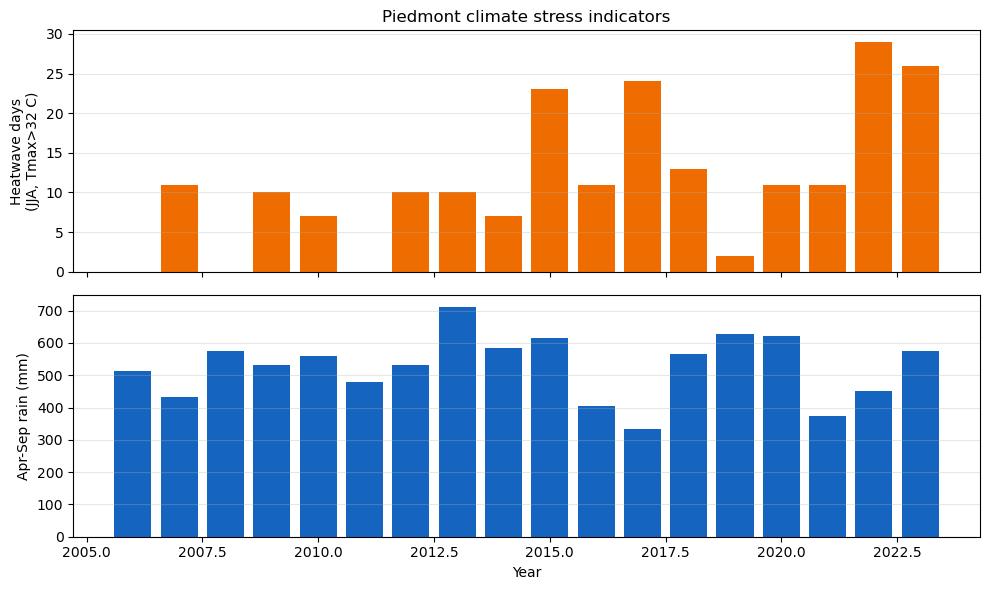

In [7]:
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].bar(climate.year, climate.summer_heatwave_days, color='#ef6c00'); ax[0].set_ylabel('Heatwave days\n(JJA, Tmax>%g C)' % config.HEAT_TMAX_THRESHOLD_C)
ax[1].bar(climate.year, climate.growing_precip_mm, color='#1565c0'); ax[1].set_ylabel('Apr-Sep rain (mm)'); ax[1].set_xlabel('Year')
for a in ax: a.grid(alpha=.3, axis='y')
ax[0].set_title('Piedmont climate stress indicators')
plt.tight_layout(); plt.show()

Output: `data/processed/piedmont_climate_indices.csv`. Next,
`03_compound_analysis.ipynb` joins this to production.